# Bank Loan & Credit Risk Analysis — Basic to Very Advanced EDA

**Role target:** Data Analyst / Data Science Fresher  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, SciPy, Statistics  
**Dataset:** `bank_loan_credit_risk_dataset.csv`

> **Dataset disclosure:** This project dataset is synthetic / created for learning and portfolio demonstration. It is not real bank customer data. Clearly disclose this in interviews.

## Business problem
Explore loan records to understand data quality, borrower profiles, repayment outcomes, possible risk indicators and business patterns. This notebook is an EDA project, not a production credit-scoring model and not proof of causation.

## How to run
1. Keep this notebook and `bank_loan_credit_risk_dataset.csv` in the same folder.
2. In VS Code, open this `.ipynb` file and select a Python kernel.
3. Run cells from top to bottom.
4. If a package is missing, run the installation cell below.


## 1. Install / import required libraries

In [1]:
# If packages are missing, uncomment and run:
# %pip install pandas numpy matplotlib seaborn scipy statsmodels scikit-learn

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import chi2_contingency, mannwhitneyu, ttest_ind, shapiro
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Load dataset

In [2]:
# Keep the CSV in the same folder as this notebook.
# If your file is elsewhere, replace the path below with your own Windows path.
file_path = "bank_loan_credit_risk_dataset.csv"

df = pd.read_csv(file_path)
print("Dataset loaded successfully.")
df.head()


Dataset loaded successfully.


,Customer_ID,Age,Annual_Income,Employment_Type,Employment_Years,Loan_Purpose,Loan_Amount,Loan_Term_Months,Credit_Score,Existing_Loans,Missed_Payments_12M,Interest_Rate,Debt_to_Income_Ratio,Loan_Status
0,CUST00001,25,"14,562.00",Salaried,4.10,Vehicle,510250,60,624.00,1,2,15.92,95.00,Default
1,CUST00002,55,"26,837.00",Salaried,2.60,Home,3091094,36,684.00,0,2,13.43,95.00,Fully Paid
2,CUST00003,50,"21,805.00",Salaried,17.80,Home,715334,36,702.00,0,0,15.37,95.00,Fully Paid
3,CUST00004,40,"17,661.00",Salaried,1.60,Vehicle,915130,36,656.00,0,1,12.22,95.00,Fully Paid
4,CUST00005,40,"29,297.00",Salaried,2.90,Business,654636,12,721.00,0,0,12.98,95.00,Fully Paid


## 3. Business understanding and data dictionary

In [3]:
print("Rows and columns:", df.shape)
print("\\nColumn names:")
print(df.columns.tolist())


Rows and columns: (2512, 14)
\nColumn names:
['Customer_ID', 'Age', 'Annual_Income', 'Employment_Type', 'Employment_Years', 'Loan_Purpose', 'Loan_Amount', 'Loan_Term_Months', 'Credit_Score', 'Existing_Loans', 'Missed_Payments_12M', 'Interest_Rate', 'Debt_to_Income_Ratio', 'Loan_Status']


| Column | Meaning |
|---|---|
| Customer_ID | Unique customer identifier |
| Age | Customer age |
| Annual_Income | Annual income |
| Employment_Type | Employment category |
| Employment_Years | Years in employment |
| Loan_Purpose | Reason for loan |
| Loan_Amount | Principal loan amount |
| Loan_Term_Months | Loan duration in months |
| Credit_Score | Credit score |
| Existing_Loans | Number of existing loans |
| Missed_Payments_12M | Missed payments in previous 12 months |
| Interest_Rate | Annual interest rate (%) |
| Debt_to_Income_Ratio | Debt-to-income ratio (%) |
| Loan_Status | Fully Paid / Default |


## 4. Initial data inspection

In [4]:
print("Shape:", df.shape)
print("\\nFirst 5 rows:")
display(df.head())
print("\\nLast 5 rows:")
display(df.tail())
print("\\nRandom 5 rows:")
display(df.sample(min(5, len(df)), random_state=42))


Shape: (2512, 14)
\nFirst 5 rows:


,Customer_ID,Age,Annual_Income,Employment_Type,Employment_Years,Loan_Purpose,Loan_Amount,Loan_Term_Months,Credit_Score,Existing_Loans,Missed_Payments_12M,Interest_Rate,Debt_to_Income_Ratio,Loan_Status
0,CUST00001,25,"14,562.00",Salaried,4.10,Vehicle,510250,60,624.00,1,2,15.92,95.00,Default
1,CUST00002,55,"26,837.00",Salaried,2.60,Home,3091094,36,684.00,0,2,13.43,95.00,Fully Paid
2,CUST00003,50,"21,805.00",Salaried,17.80,Home,715334,36,702.00,0,0,15.37,95.00,Fully Paid
3,CUST00004,40,"17,661.00",Salaried,1.60,Vehicle,915130,36,656.00,0,1,12.22,95.00,Fully Paid
4,CUST00005,40,"29,297.00",Salaried,2.90,Business,654636,12,721.00,0,0,12.98,95.00,Fully Paid


\nLast 5 rows:


,Customer_ID,Age,Annual_Income,Employment_Type,Employment_Years,Loan_Purpose,Loan_Amount,Loan_Term_Months,Credit_Score,Existing_Loans,Missed_Payments_12M,Interest_Rate,Debt_to_Income_Ratio,Loan_Status
2507,CUST00922,46,"43,926.00",Salaried,8.10,Business,571518,60,673.00,1,2,11.94,95.00,Default
2508,CUST00064,64,"113,168.00",Contract,10.40,Education,837555,24,752.00,1,0,7.07,95.00,Fully Paid
2509,CUST02219,33,"44,151.00",Contract,8.70,Home,691936,36,734.00,0,0,14.34,95.00,Default
2510,CUST01969,58,"36,946.00",Business,5.00,Business,435738,60,737.00,2,1,12.42,95.00,Fully Paid
2511,CUST01043,39,"60,983.00",Salaried,8.40,Business,1232156,36,588.00,1,1,16.19,95.00,Default


\nRandom 5 rows:


,Customer_ID,Age,Annual_Income,Employment_Type,Employment_Years,Loan_Purpose,Loan_Amount,Loan_Term_Months,Credit_Score,Existing_Loans,Missed_Payments_12M,Interest_Rate,Debt_to_Income_Ratio,Loan_Status
2081,CUST02082,25,"70,037.00",Business,10.90,Personal,1936693,60,592.00,0,4,14.26,95.00,Default
433,CUST00434,26,"91,161.00",Salaried,15.50,Personal,548364,24,694.00,1,0,13.32,95.00,Fully Paid
1724,CUST01725,45,"42,890.00",Contract,9.90,Medical,1014216,60,672.00,0,0,16.25,95.00,Fully Paid
1251,CUST01252,39,"35,862.00",Self-Employed,9.70,Education,3774468,36,609.00,2,2,15.03,95.00,Default
93,CUST00094,38,"93,976.00",Contract,8.30,Personal,870752,60,750.00,2,0,10.45,95.00,Default


In [5]:
print("Data types and non-null counts:")
df.info()


Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 2512 entries, 0 to 2511
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Customer_ID           2512 non-null   str    
 1   Age                   2512 non-null   int64  
 2   Annual_Income         2482 non-null   float64
 3   Employment_Type       2492 non-null   str    
 4   Employment_Years      2512 non-null   float64
 5   Loan_Purpose          2497 non-null   str    
 6   Loan_Amount           2512 non-null   int64  
 7   Loan_Term_Months      2512 non-null   int64  
 8   Credit_Score          2487 non-null   float64
 9   Existing_Loans        2512 non-null   int64  
 10  Missed_Payments_12M   2512 non-null   int64  
 11  Interest_Rate         2512 non-null   float64
 12  Debt_to_Income_Ratio  2512 non-null   float64
 13  Loan_Status           2512 non-null   str    
dtypes: float64(5), int64(5), str(4)
memory usage: 357.3

In [6]:
print("Descriptive statistics - numeric:")
display(df.describe().T)
print("\\nDescriptive statistics - all columns:")
display(df.describe(include="all").T)


Descriptive statistics - numeric:


,count,mean,std,min,25%,50%,75%,max
Age,"2,512.00",42.93,12.99,21.00,32.00,43.00,54.00,65.00
Annual_Income,"2,482.00","58,160.81","29,571.96","12,000.00","37,565.00","52,272.50","71,510.00","229,002.00"
Employment_Years,"2,512.00",7.49,4.72,0.20,4.10,6.50,9.90,35.00
Loan_Amount,"2,512.00","1,058,984.91","739,816.36","67,909.00","549,159.25","846,640.50","1,341,087.50","6,000,000.00"
Loan_Term_Months,"2,512.00",40.35,14.86,12.00,36.00,36.00,60.00,60.00
Credit_Score,"2,487.00",693.21,66.21,449.00,647.00,692.00,739.00,850.00
Existing_Loans,"2,512.00",1.17,1.09,0.00,0.00,1.00,2.00,6.00
Missed_Payments_12M,"2,512.00",0.71,0.87,0.00,0.00,0.00,1.00,6.00
Interest_Rate,"2,512.00",12.67,2.24,6.00,11.20,12.68,14.15,21.41
Debt_to_Income_Ratio,"2,512.00",94.88,1.84,38.57,95.00,95.00,95.00,95.00


\nDescriptive statistics - all columns:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Customer_ID,2512,2500,CUST00064,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,"2,512.00",NaN,NaN,NaN,42.93,12.99,21.00,32.00,43.00,54.00,65.00
Annual_Income,"2,482.00",NaN,NaN,NaN,"58,160.81","29,571.96","12,000.00","37,565.00","52,272.50","71,510.00","229,002.00"
Employment_Type,2492,4,Salaried,1355,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Employment_Years,"2,512.00",NaN,NaN,NaN,7.49,4.72,0.20,4.10,6.50,9.90,35.00
Loan_Purpose,2497,6,Personal,707,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Loan_Amount,"2,512.00",NaN,NaN,NaN,"1,058,984.91","739,816.36","67,909.00","549,159.25","846,640.50","1,341,087.50","6,000,000.00"
Loan_Term_Months,"2,512.00",NaN,NaN,NaN,40.35,14.86,12.00,36.00,36.00,60.00,60.00
Credit_Score,"2,487.00",NaN,NaN,NaN,693.21,66.21,449.00,647.00,692.00,739.00,850.00
Existing_Loans,"2,512.00",NaN,NaN,NaN,1.17,1.09,0.00,0.00,1.00,2.00,6.00


## 5. Data quality assessment

In [7]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percent": (df.isna().mean() * 100).round(2),
    "Data_Type": df.dtypes.astype(str)
}).sort_values("Missing_Percent", ascending=False)

display(missing_summary)


,Missing_Count,Missing_Percent,Data_Type
Annual_Income,30,1.19,float64
Credit_Score,25,1.00,float64
Employment_Type,20,0.80,str
Loan_Purpose,15,0.60,str
Age,0,0.00,int64
Customer_ID,0,0.00,str
Employment_Years,0,0.00,float64
Loan_Amount,0,0.00,int64
Loan_Term_Months,0,0.00,int64
Existing_Loans,0,0.00,int64


In [8]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate Customer_ID values:", df["Customer_ID"].duplicated().sum())


Exact duplicate rows: 12
Duplicate Customer_ID values: 12


In [9]:
# Check unique values in categorical columns
cat_cols = df.select_dtypes(include=["object", "category"]).columns
for col in cat_cols:
    print(f"\\n{col} - unique values:")
    print(df[col].value_counts(dropna=False))


\nCustomer_ID - unique values:
Customer_ID
CUST00064    2
CUST00171    2
CUST00241    2
CUST00433    2
CUST00475    2
            ..
CUST02496    1
CUST02497    1
CUST02498    1
CUST02499    1
CUST02500    1
Name: count, Length: 2500, dtype: int64
\nEmployment_Type - unique values:
Employment_Type
Salaried         1355
Business          470
Self-Employed     448
Contract          219
NaN                20
Name: count, dtype: int64
\nLoan_Purpose - unique values:
Loan_Purpose
Personal     707
Home         565
Vehicle      419
Business     327
Education    298
Medical      181
NaN           15
Name: count, dtype: int64
\nLoan_Status - unique values:
Loan_Status
Fully Paid    1313
Default       1199
Name: count, dtype: int64


In [10]:
# Check numeric ranges for suspicious values
numeric_cols = df.select_dtypes(include=np.number).columns
display(df[numeric_cols].agg(["min", "max", "mean", "median"]).T)


,min,max,mean,median
Age,21.00,65.00,42.93,43.00
Annual_Income,"12,000.00","229,002.00","58,160.81","52,272.50"
Employment_Years,0.20,35.00,7.49,6.50
Loan_Amount,"67,909.00","6,000,000.00","1,058,984.91","846,640.50"
Loan_Term_Months,12.00,60.00,40.35,36.00
Credit_Score,449.00,850.00,693.21,692.00
Existing_Loans,0.00,6.00,1.17,1.00
Missed_Payments_12M,0.00,6.00,0.71,0.00
Interest_Rate,6.00,21.41,12.67,12.68
Debt_to_Income_Ratio,38.57,95.00,94.88,95.00


## 6. Data cleaning

**Cleaning decisions:** remove exact duplicate records; fill numeric missing values with median; fill categorical missing values with mode. These are demonstration choices. Real lending data requires documented, domain-approved rules. For predictive modelling, imputation must be learned from training data only.

In [11]:
data = df.copy()

# Remove exact duplicate rows
data = data.drop_duplicates().copy()

# Missing value treatment
numeric_cols = data.select_dtypes(include=np.number).columns.tolist()
categorical_cols = data.select_dtypes(include=["object", "category"]).columns.tolist()

for col in numeric_cols:
    data[col] = data[col].fillna(data[col].median())

for col in categorical_cols:
    if data[col].isna().any():
        mode_value = data[col].mode(dropna=True)
        if not mode_value.empty:
            data[col] = data[col].fillna(mode_value.iloc[0])

print("Original shape:", df.shape)
print("Cleaned shape:", data.shape)
print("Remaining missing values:", data.isna().sum().sum())
print("Remaining exact duplicates:", data.duplicated().sum())


Original shape: (2512, 14)
Cleaned shape: (2500, 14)
Remaining missing values: 0
Remaining exact duplicates: 0


## 7. Validate and standardise data

In [12]:
# Standardise text labels (trim extra spaces)
for col in data.select_dtypes(include="object").columns:
    data[col] = data[col].str.strip()

# Validate expected target labels
print(data["Loan_Status"].value_counts(dropna=False))
print("Unexpected Loan_Status values:",
      set(data["Loan_Status"].dropna().unique()) - {"Fully Paid", "Default"})


Loan_Status
Fully Paid    1309
Default       1191
Name: count, dtype: int64
Unexpected Loan_Status values: set()


In [13]:
# Basic logical checks - inspect rather than silently delete
checks = {
    "Age <= 0": (data["Age"] <= 0).sum(),
    "Annual_Income <= 0": (data["Annual_Income"] <= 0).sum(),
    "Loan_Amount <= 0": (data["Loan_Amount"] <= 0).sum(),
    "Credit_Score outside 300-900": (~data["Credit_Score"].between(300, 900)).sum(),
    "Loan_Term_Months <= 0": (data["Loan_Term_Months"] <= 0).sum(),
    "Interest_Rate <= 0": (data["Interest_Rate"] <= 0).sum()
}
pd.Series(checks, name="Invalid_Count")


Age <= 0                        0
Annual_Income <= 0              0
Loan_Amount <= 0                0
Credit_Score outside 300-900    0
Loan_Term_Months <= 0           0
Interest_Rate <= 0              0
Name: Invalid_Count, dtype: int64

## 8. Feature engineering

In [14]:
# Create target indicator
data["Default_Flag"] = (data["Loan_Status"] == "Default").astype(int)

# Estimate EMI using reducing-balance formula
monthly_rate = data["Interest_Rate"] / 1200
months = data["Loan_Term_Months"]
principal = data["Loan_Amount"]

data["Estimated_EMI"] = (
    principal * monthly_rate * (1 + monthly_rate) ** months
    / ((1 + monthly_rate) ** months - 1)
)

# Monthly income and affordability ratios
data["Monthly_Income"] = data["Annual_Income"] / 12
data["EMI_to_Income_Pct"] = (
    data["Estimated_EMI"] / data["Monthly_Income"] * 100
)
data["Loan_to_Income"] = data["Loan_Amount"] / data["Annual_Income"]

# Customer age group
data["Age_Group"] = pd.cut(
    data["Age"],
    bins=[18, 25, 35, 45, 55, 100],
    labels=["19-25", "26-35", "36-45", "46-55", "56+"],
    include_lowest=True
)

display(data.head())


,Customer_ID,Age,Annual_Income,Employment_Type,Employment_Years,Loan_Purpose,Loan_Amount,Loan_Term_Months,Credit_Score,Existing_Loans,Missed_Payments_12M,Interest_Rate,Debt_to_Income_Ratio,Loan_Status,Default_Flag,Estimated_EMI,Monthly_Income,EMI_to_Income_Pct,Loan_to_Income,Age_Group
0,CUST00001,25,"14,562.00",Salaried,4.10,Vehicle,510250,60,624.00,1,2,15.92,95.00,Default,1,"12,386.61","1,213.50","1,020.73",35.04,19-25
1,CUST00002,55,"26,837.00",Salaried,2.60,Home,3091094,36,684.00,0,2,13.43,95.00,Fully Paid,0,"104,792.54","2,236.42","4,685.73",115.18,46-55
2,CUST00003,50,"21,805.00",Salaried,17.80,Home,715334,36,702.00,0,0,15.37,95.00,Fully Paid,0,"24,927.10","1,817.08","1,371.82",32.81,46-55
3,CUST00004,40,"17,661.00",Salaried,1.60,Vehicle,915130,36,656.00,0,1,12.22,95.00,Fully Paid,0,"30,491.66","1,471.75","2,071.80",51.82,36-45
4,CUST00005,40,"29,297.00",Salaried,2.90,Business,654636,12,721.00,0,0,12.98,95.00,Fully Paid,0,"58,464.16","2,441.42","2,394.68",22.34,36-45


## 9. Univariate analysis — categorical variables

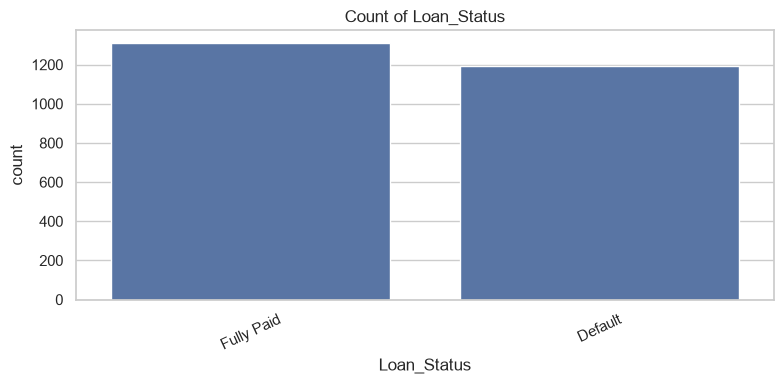

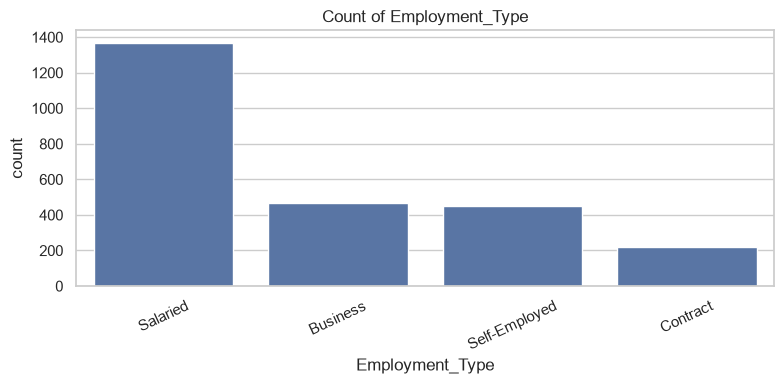

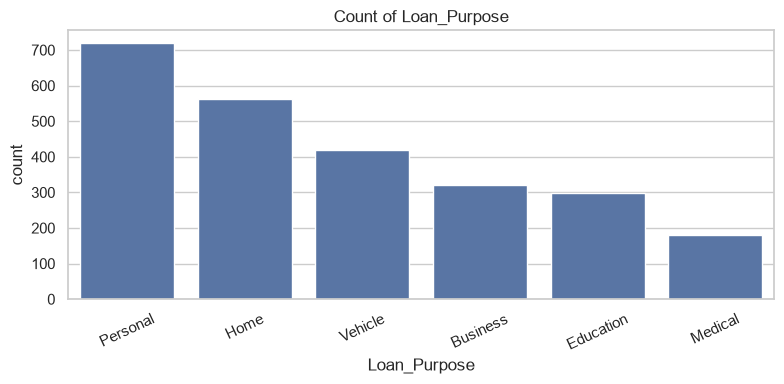

In [15]:
for col in ["Loan_Status", "Employment_Type", "Loan_Purpose"]:
    plt.figure(figsize=(8, 4))
    order = data[col].value_counts().index
    sns.countplot(data=data, x=col, order=order)
    plt.title(f"Count of {col}")
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.show()


## 10. Univariate analysis — numerical variables

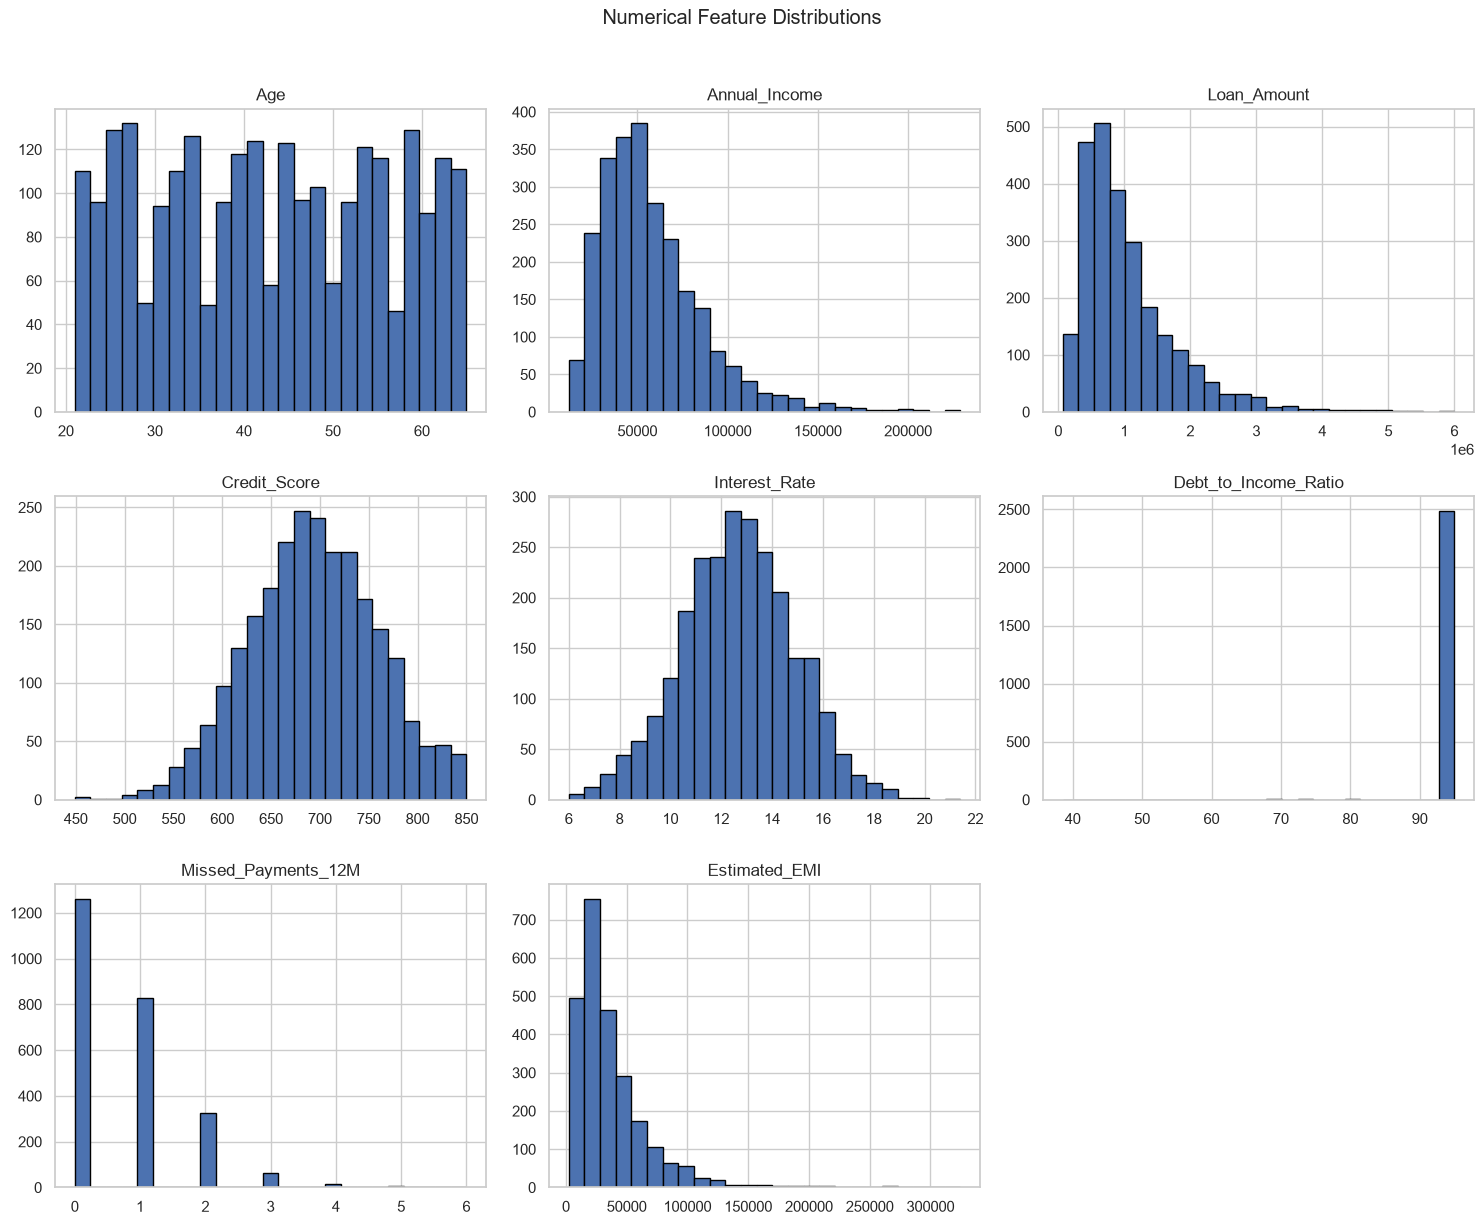

In [16]:
num_plot_cols = [
    "Age", "Annual_Income", "Loan_Amount", "Credit_Score",
    "Interest_Rate", "Debt_to_Income_Ratio",
    "Missed_Payments_12M", "Estimated_EMI"
]

data[num_plot_cols].hist(figsize=(15, 12), bins=25, edgecolor="black")
plt.suptitle("Numerical Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()


In [17]:
# Summary measures
summary = data[num_plot_cols].agg(["count", "mean", "median", "std", "min", "max", "skew"]).T
display(summary)


,count,mean,median,std,min,max,skew
Age,"2,500.00",42.92,43.00,12.99,21.00,65.00,0.01
Annual_Income,"2,500.00","58,054.70","52,275.00","29,379.79","12,000.00","229,002.00",1.56
Loan_Amount,"2,500.00","1,058,415.04","846,640.50","739,605.21","67,909.00","6,000,000.00",1.89
Credit_Score,"2,500.00",693.29,692.00,65.88,449.00,850.00,-0.05
Interest_Rate,"2,500.00",12.67,12.67,2.24,6.00,21.41,0.01
Debt_to_Income_Ratio,"2,500.00",94.88,95.00,1.84,38.57,95.00,-19.66
Missed_Payments_12M,"2,500.00",0.71,0.00,0.87,0.00,6.00,1.35
Estimated_EMI,"2,500.00","37,912.19","28,082.55","33,698.41","2,325.26","324,644.18",3.19


## 11. Bivariate analysis — categorical vs target

In [18]:
for col in ["Employment_Type", "Loan_Purpose", "Age_Group"]:
    rate = data.groupby(col, observed=False)["Default_Flag"].agg(
        Customers="count", Default_Rate="mean"
    )
    rate["Default_Rate"] = rate["Default_Rate"] * 100
    print(f"\\nDefault rate by {col}:")
    display(rate.sort_values("Default_Rate", ascending=False).round(2))


\nDefault rate by Employment_Type:


,Customers,Default_Rate
Employment_Type,,
Business,466,50.43
Salaried,1369,47.11
Self-Employed,448,47.10
Contract,217,46.08


\nDefault rate by Loan_Purpose:


,Customers,Default_Rate
Loan_Purpose,,
Vehicle,418,50.48
Personal,719,49.37
Medical,181,48.07
Home,563,46.36
Business,322,45.34
Education,297,44.11


\nDefault rate by Age_Group:


,Customers,Default_Rate
Age_Group,,
19-25,273,52.01
36-45,568,51.41
56+,553,47.74
26-35,574,45.12
46-55,532,43.98


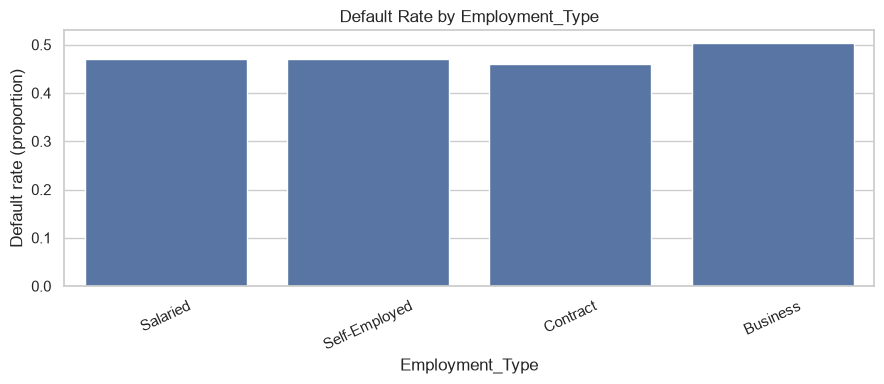

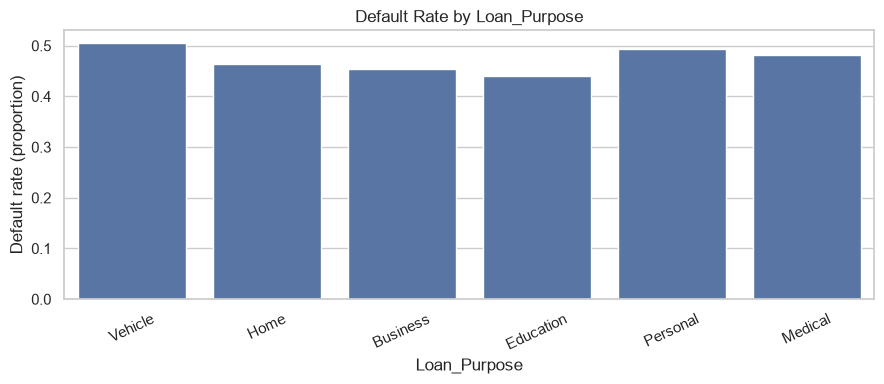

In [19]:
for col in ["Employment_Type", "Loan_Purpose"]:
    plt.figure(figsize=(9, 4))
    sns.barplot(data=data, x=col, y="Default_Flag", errorbar=None)
    plt.title(f"Default Rate by {col}")
    plt.ylabel("Default rate (proportion)")
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.show()


## 12. Bivariate analysis — numerical vs target

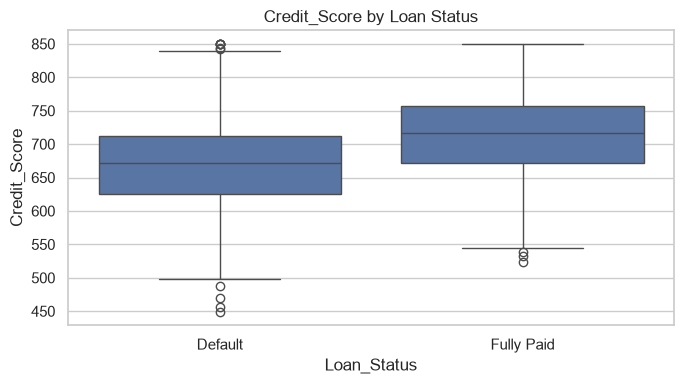

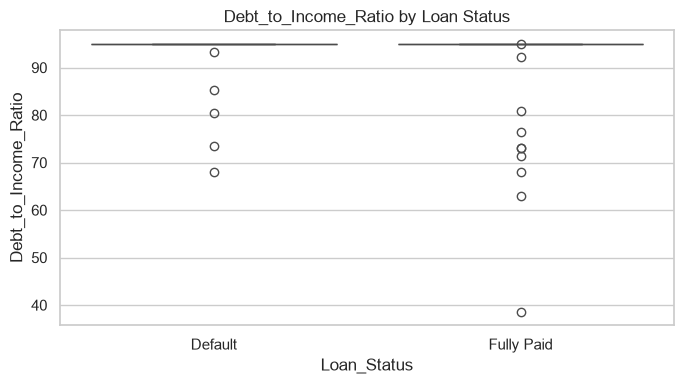

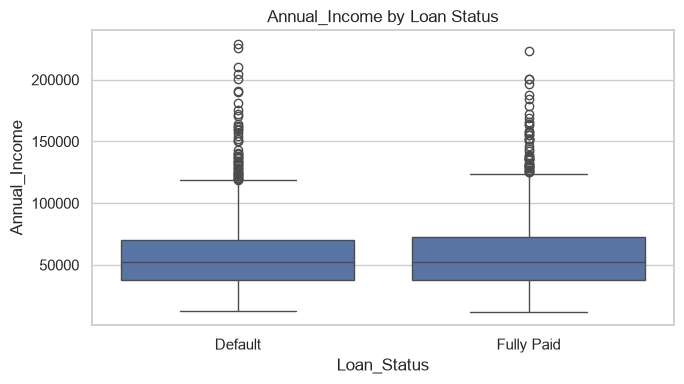

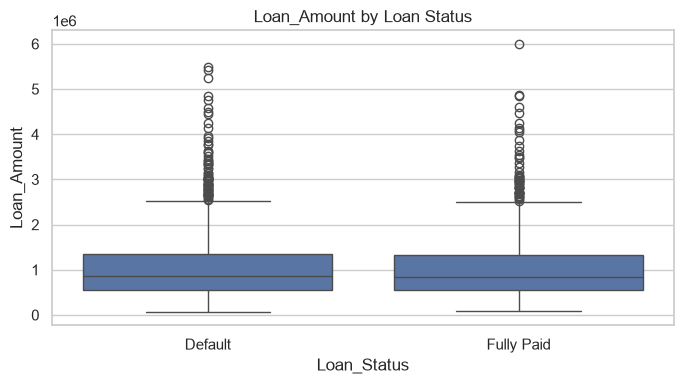

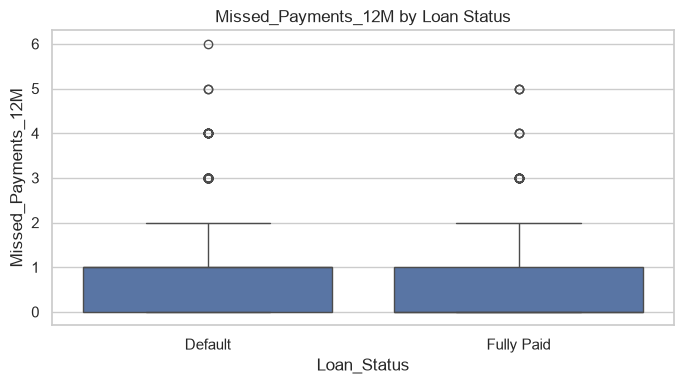

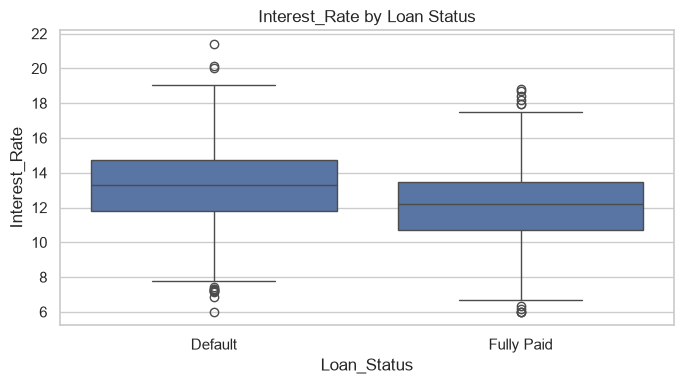

In [20]:
for col in ["Credit_Score", "Debt_to_Income_Ratio", "Annual_Income",
            "Loan_Amount", "Missed_Payments_12M", "Interest_Rate"]:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=data, x="Loan_Status", y=col)
    plt.title(f"{col} by Loan Status")
    plt.tight_layout()
    plt.show()


## 13. Multivariate analysis

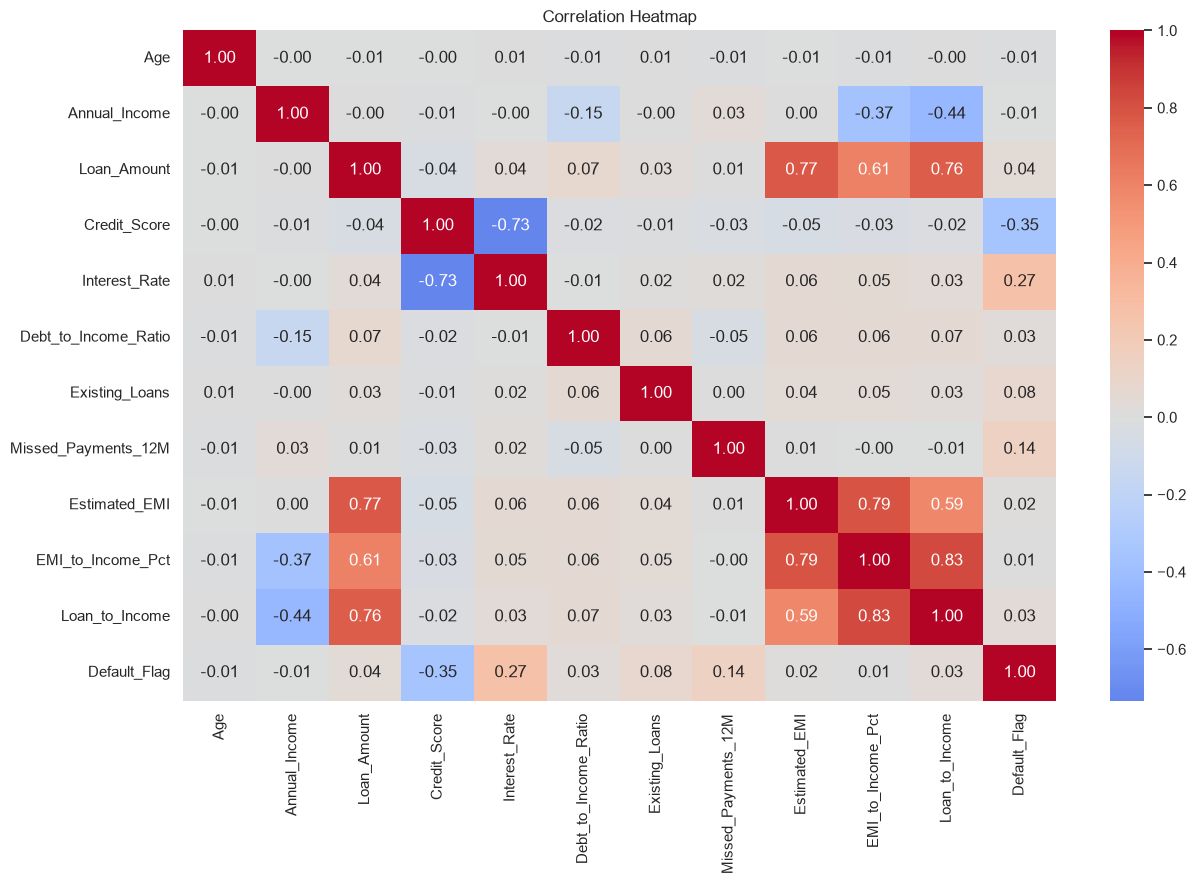

In [21]:
corr_cols = [
    "Age", "Annual_Income", "Loan_Amount", "Credit_Score",
    "Interest_Rate", "Debt_to_Income_Ratio", "Existing_Loans",
    "Missed_Payments_12M", "Estimated_EMI", "EMI_to_Income_Pct",
    "Loan_to_Income", "Default_Flag"
]
corr = data[corr_cols].corr(numeric_only=True)

plt.figure(figsize=(13, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


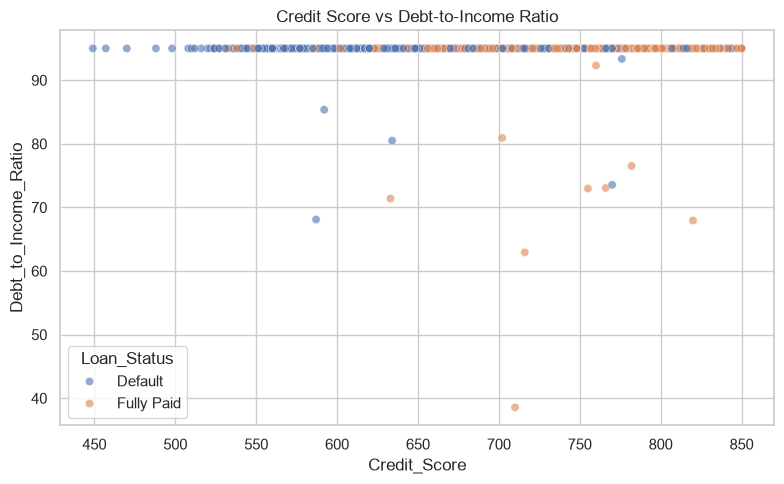

In [23]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=data, x="Credit_Score", y="Debt_to_Income_Ratio",
    hue="Loan_Status", alpha=0.6
)
plt.title("Credit Score vs Debt-to-Income Ratio")
plt.tight_layout()
plt.show()


## 14. Outlier detection — IQR method

In [24]:
def iqr_outlier_report(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outlier_count = ((series < lower) | (series > upper)).sum()
    return pd.Series({
        "Q1": q1, "Q3": q3, "IQR": iqr,
        "Lower_Limit": lower, "Upper_Limit": upper,
        "Outlier_Count": outlier_count,
        "Outlier_Percent": outlier_count / len(series) * 100
    })

outlier_cols = ["Annual_Income", "Loan_Amount", "Credit_Score",
                "Debt_to_Income_Ratio", "Estimated_EMI"]
display(pd.DataFrame({col: iqr_outlier_report(data[col]) for col in outlier_cols}).T)


,Q1,Q3,IQR,Lower_Limit,Upper_Limit,Outlier_Count,Outlier_Percent
Annual_Income,"37,690.75","71,242.25","33,551.50","-12,636.50","121,569.50",96.00,3.84
Loan_Amount,"548,351.25","1,341,087.50","792,736.25","-640,753.12","2,530,191.88",122.00,4.88
Credit_Score,648.00,738.00,90.00,513.00,873.00,8.00,0.32
Debt_to_Income_Ratio,95.00,95.00,0.00,95.00,95.00,15.00,0.60
Estimated_EMI,"17,015.22","47,712.44","30,697.22","-29,030.61","93,758.26",140.00,5.60


## 15. Outlier detection — Z-score method

In [25]:
zscore_cols = ["Annual_Income", "Loan_Amount", "Debt_to_Income_Ratio"]
for col in zscore_cols:
    z = np.abs(stats.zscore(data[col], nan_policy="omit"))
    print(col, "| Z-score > 3 count:", int((z > 3).sum()))


Annual_Income | Z-score > 3 count: 43
Loan_Amount | Z-score > 3 count: 43
Debt_to_Income_Ratio | Z-score > 3 count: 12


**Interpretation:** IQR and Z-score are screening techniques, not automatic deletion rules. Loan amounts and incomes may be genuinely high. Investigate context before removing or capping observations.

## 16. Distribution analysis — KDE, PDF and CDF

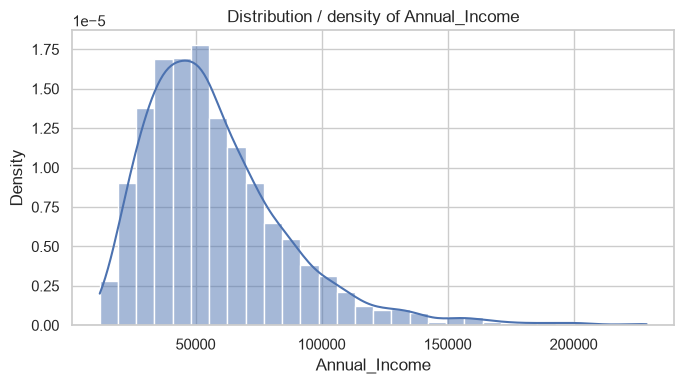

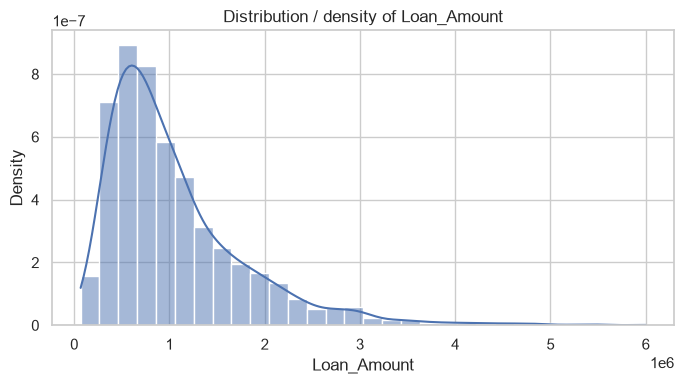

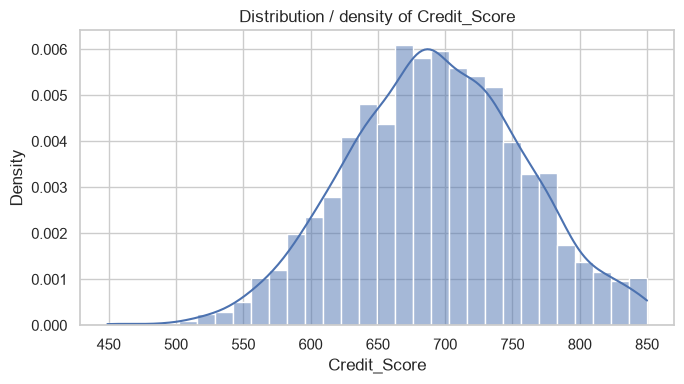

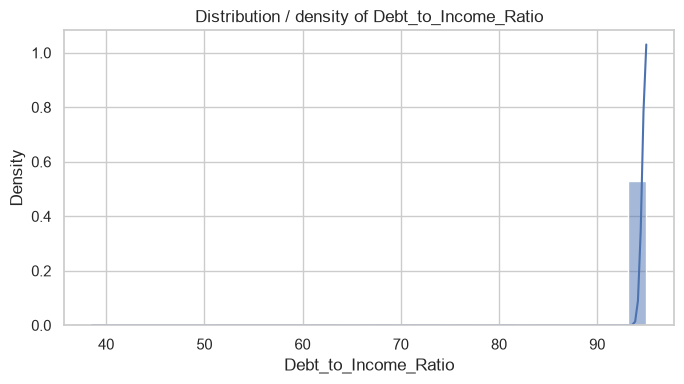

In [26]:
for col in ["Annual_Income", "Loan_Amount", "Credit_Score", "Debt_to_Income_Ratio"]:
    plt.figure(figsize=(7, 4))
    sns.histplot(data[col], kde=True, stat="density", bins=30)
    plt.title(f"Distribution / density of {col}")
    plt.tight_layout()
    plt.show()


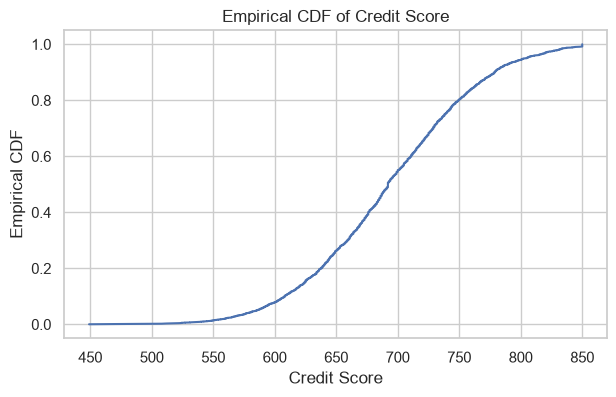

In [27]:
# Empirical CDF for Credit Score
x = np.sort(data["Credit_Score"].dropna())
y = np.arange(1, len(x) + 1) / len(x)

plt.figure(figsize=(7, 4))
plt.plot(x, y)
plt.xlabel("Credit Score")
plt.ylabel("Empirical CDF")
plt.title("Empirical CDF of Credit Score")
plt.grid(True)
plt.show()


## 17. Skewness and kurtosis

In [28]:
distribution_stats = pd.DataFrame({
    "Skewness": data[num_plot_cols].skew(),
    "Kurtosis_Excess": data[num_plot_cols].kurtosis()
})
display(distribution_stats)


,Skewness,Kurtosis_Excess
Age,0.01,-1.20
Annual_Income,1.56,3.93
Loan_Amount,1.89,5.15
Credit_Score,-0.05,-0.15
Interest_Rate,0.01,0.01
Debt_to_Income_Ratio,-19.66,461.67
Missed_Payments_12M,1.35,2.28
Estimated_EMI,3.19,16.47


- Skewness near 0 suggests approximate symmetry.
- Positive skew means a longer right tail.
- Negative skew means a longer left tail.
- Pandas `kurtosis()` reports excess kurtosis (normal distribution is approximately 0).
- A non-zero skew/kurtosis does not by itself make data unusable.

## 18. Gaussian / normality checks

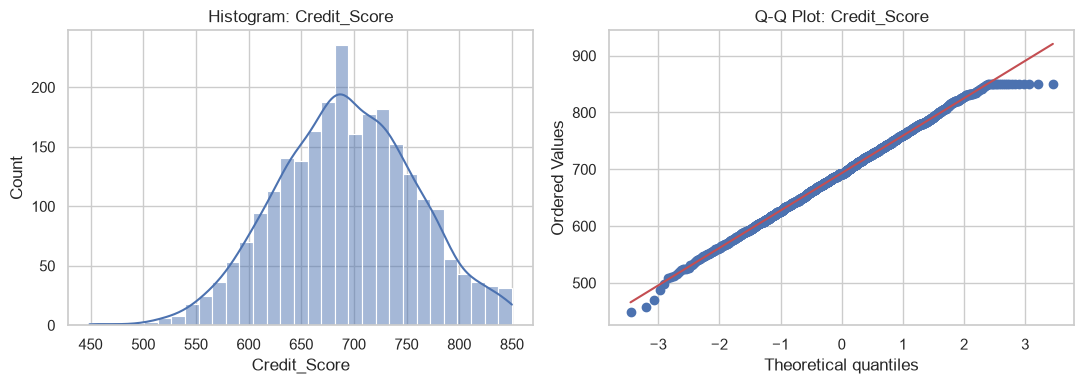

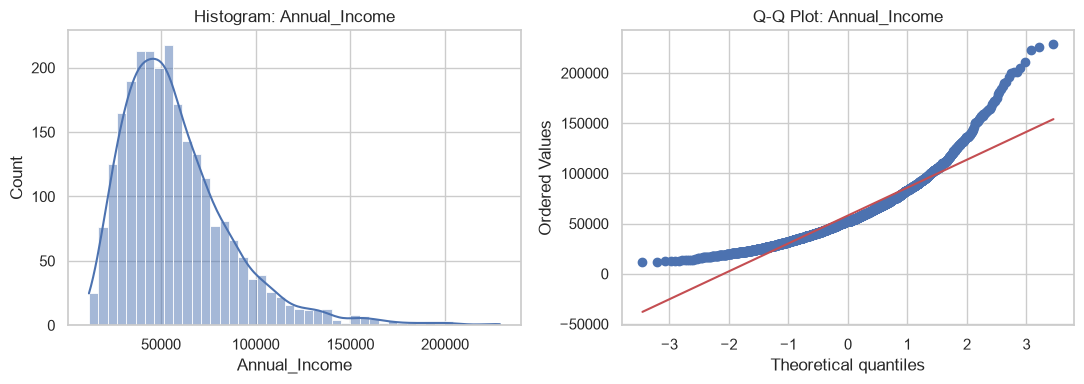

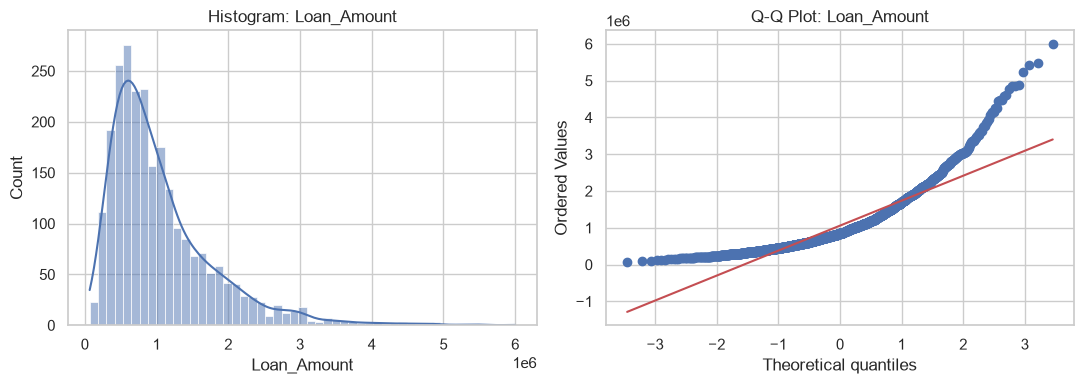

In [29]:
# Visual normality check with histogram and Q-Q plot
for col in ["Credit_Score", "Annual_Income", "Loan_Amount"]:
    values = data[col].dropna()
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    sns.histplot(values, kde=True, ax=axes[0])
    axes[0].set_title(f"Histogram: {col}")
    stats.probplot(values, dist="norm", plot=axes[1])
    axes[1].set_title(f"Q-Q Plot: {col}")
    plt.tight_layout()
    plt.show()


In [30]:
# Shapiro-Wilk is sensitive for large samples; use a reproducible sample up to 5000.
for col in ["Credit_Score", "Annual_Income", "Loan_Amount"]:
    values = data[col].dropna()
    sample = values.sample(min(5000, len(values)), random_state=42)
    statistic, p_value = shapiro(sample)
    print(f"{col}: statistic={statistic:.4f}, p-value={p_value:.6f}")
    print("Reject normality at 5%?" , p_value < 0.05)


Credit_Score: statistic=0.9978, p-value=0.001499
Reject normality at 5%? True
Annual_Income: statistic=0.8934, p-value=0.000000
Reject normality at 5%? True
Loan_Amount: statistic=0.8406, p-value=0.000000
Reject normality at 5%? True


**Caution:** With large samples, normality tests can reject small deviations. Combine plots, domain knowledge and the intended statistical method; do not rely on one p-value.

## 19. Central Limit Theorem (CLT) demonstration

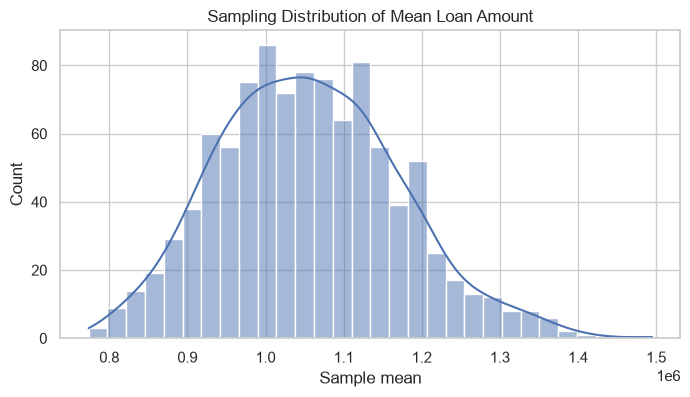

Mean of sample means: 1055651.050175
Population mean: 1058415.0352
Theoretical standard error: 116941.85110804421


In [31]:
# Demonstrate the sampling distribution of the sample mean of Loan_Amount
population = data["Loan_Amount"].dropna().to_numpy()
rng = np.random.default_rng(42)

sample_means = []
sample_size = 40
number_of_samples = 1000

for _ in range(number_of_samples):
    sample = rng.choice(population, size=sample_size, replace=True)
    sample_means.append(sample.mean())

plt.figure(figsize=(8, 4))
sns.histplot(sample_means, kde=True, bins=30)
plt.title("Sampling Distribution of Mean Loan Amount")
plt.xlabel("Sample mean")
plt.show()

print("Mean of sample means:", np.mean(sample_means))
print("Population mean:", np.mean(population))
print("Theoretical standard error:", np.std(population, ddof=1) / np.sqrt(sample_size))


## 20. Confidence interval for default rate

In [32]:
default_count = int(data["Default_Flag"].sum())
total_count = len(data)
default_rate = default_count / total_count

ci_low, ci_high = proportion_confint(
    count=default_count, nobs=total_count, alpha=0.05, method="wilson"
)

print(f"Observed default rate: {default_rate*100:.2f}%")
print(f"95% Wilson CI: ({ci_low*100:.2f}%, {ci_high*100:.2f}%)")


Observed default rate: 47.64%
95% Wilson CI: (45.69%, 49.60%)


## 21. Hypothesis testing — numerical variables

Example question: Is the average credit score different between fully-paid and defaulted loans?

- H0: The two groups have equal mean credit scores.
- H1: The two groups have different mean credit scores.

Welch's t-test does not assume equal group variances. Interpret the p-value with effect size and business context.

In [33]:
paid_scores = data.loc[data["Loan_Status"] == "Fully Paid", "Credit_Score"].dropna()
default_scores = data.loc[data["Loan_Status"] == "Default", "Credit_Score"].dropna()

t_stat, p_value = ttest_ind(paid_scores, default_scores, equal_var=False)
print("Welch t-statistic:", t_stat)
print("p-value:", p_value)
print("Decision at alpha=0.05:", "Reject H0" if p_value < 0.05 else "Fail to reject H0")
print("Mean score - fully paid:", paid_scores.mean())
print("Mean score - default:", default_scores.mean())


Welch t-statistic: 18.504804126169823
p-value: 1.1017392736102004e-71
Decision at alpha=0.05: Reject H0
Mean score - fully paid: 715.1306340718105
Mean score - default: 669.2854743912678


## 22. Non-parametric test — Mann-Whitney U

In [34]:
u_stat, p_value = mannwhitneyu(
    paid_scores, default_scores, alternative="two-sided"
)
print("Mann-Whitney U:", u_stat)
print("p-value:", p_value)


Mann-Whitney U: 1090884.0
p-value: 7.363070450112609e-67


## 23. Hypothesis testing — categorical variables (Chi-square)

In [35]:
contingency = pd.crosstab(data["Employment_Type"], data["Loan_Status"])
chi2, p_value, dof, expected = chi2_contingency(contingency)

print("Contingency table:")
display(contingency)
print("Chi-square:", chi2)
print("Degrees of freedom:", dof)
print("p-value:", p_value)
print("Decision at alpha=0.05:", "Evidence of association" if p_value < 0.05 else "Insufficient evidence of association")


Contingency table:


Loan_Status,Default,Fully Paid
Employment_Type,,
Business,235,231
Contract,100,117
Salaried,645,724
Self-Employed,211,237


Chi-square: 1.8684251680149535
Degrees of freedom: 3
p-value: 0.6001592257890249
Decision at alpha=0.05: Insufficient evidence of association


## 24. Compare default proportions — two-proportion z-test

In [36]:
# Compare default proportion for customers with at least one missed payment vs none
group_a = data["Missed_Payments_12M"] > 0
count = np.array([
    data.loc[group_a, "Default_Flag"].sum(),
    data.loc[~group_a, "Default_Flag"].sum()
])
nobs = np.array([group_a.sum(), (~group_a).sum()])

z_stat, p_value = proportions_ztest(count, nobs)
print("Defaults / sample sizes:", count, nobs)
print("Default rates:", count / nobs)
print("z-statistic:", z_stat)
print("p-value:", p_value)


Defaults / sample sizes: [666 525] [1238 1262]
Default rates: [0.53796446 0.41600634]
z-statistic: 6.104428621629869
p-value: 1.0316908315291988e-09


## 25. Risk segmentation

In [37]:
data["Credit_Score_Band"] = pd.cut(
    data["Credit_Score"],
    bins=[0, 579, 669, 739, 799, 900],
    labels=["Poor", "Fair", "Good", "Very Good", "Excellent"]
)

risk_summary = data.groupby("Credit_Score_Band", observed=False).agg(
    Customer_Count=("Customer_ID", "count"),
    Default_Count=("Default_Flag", "sum"),
    Default_Rate=("Default_Flag", "mean"),
    Average_Loan=("Loan_Amount", "mean"),
    Average_DTI=("Debt_to_Income_Ratio", "mean")
)
risk_summary["Default_Rate"] *= 100
display(risk_summary.round(2))


,Customer_Count,Default_Count,Default_Rate,Average_Loan,Average_DTI
Credit_Score_Band,,,,,
Poor,105,85,80.95,"1,021,613.30",95.00
Fair,787,500,63.53,"1,088,385.68",94.91
Good,994,452,45.47,"1,072,585.75",94.90
Very Good,473,132,27.91,"1,017,435.30",94.81
Excellent,141,22,15.60,"956,110.09",94.81


In [38]:
data["DTI_Band"] = pd.cut(
    data["Debt_to_Income_Ratio"],
    bins=[0, 20, 35, 50, 100],
    labels=["Low (<=20)", "Moderate (20-35)", "High (35-50)", "Very High (>50)"],
    include_lowest=True
)

dti_risk = data.groupby("DTI_Band", observed=False).agg(
    Customers=("Customer_ID", "count"),
    Default_Rate=("Default_Flag", "mean")
)
dti_risk["Default_Rate"] *= 100
display(dti_risk.round(2))


,Customers,Default_Rate
DTI_Band,,
Low (<=20),0,NaN
Moderate (20-35),0,NaN
High (35-50),1,0.00
Very High (>50),2499,47.66


## 26. Advanced correlation and multicollinearity (VIF)

VIF is a diagnostic for linear dependence among predictors. Do not include identifiers or the target in the predictor matrix. High VIF does not automatically mean a variable must be removed; use domain knowledge.

In [39]:
vif_features = [
    "Age", "Annual_Income", "Loan_Amount", "Credit_Score",
    "Interest_Rate", "Debt_to_Income_Ratio",
    "Existing_Loans", "Missed_Payments_12M"
]
X_vif = data[vif_features].replace([np.inf, -np.inf], np.nan).dropna()
X_vif = add_constant(X_vif)

vif_table = pd.DataFrame({
    "Feature": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i)
            for i in range(X_vif.shape[1])]
})
display(vif_table)


,Feature,VIF
0,const,"3,384.56"
1,Age,1.00
2,Annual_Income,1.03
3,Loan_Amount,1.01
4,Credit_Score,2.17
5,Interest_Rate,2.17
6,Debt_to_Income_Ratio,1.04
7,Existing_Loans,1.00
8,Missed_Payments_12M,1.00


## 27. Optional baseline model — exploratory only

This optional section demonstrates a simple classification baseline. It is not required to call the project an EDA project. It uses a stratified train/test split and a preprocessing pipeline to avoid fitting imputers/scalers on the test set. Do not present this as a production-ready credit model.

In [40]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

features = [
    "Age", "Annual_Income", "Employment_Type", "Employment_Years",
    "Loan_Purpose", "Loan_Amount", "Loan_Term_Months",
    "Credit_Score", "Existing_Loans", "Missed_Payments_12M",
    "Interest_Rate", "Debt_to_Income_Ratio"
]
X = data[features]
y = data["Default_Flag"]

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, zero_division=0))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.66      0.67      0.66       262
           1       0.63      0.62      0.62       238

    accuracy                           0.64       500
   macro avg       0.64      0.64      0.64       500
weighted avg       0.64      0.64      0.64       500

ROC-AUC: 0.6922
Confusion matrix:
[[175  87]
 [ 91 147]]


## 28. Final KPI summary

In [41]:
kpis = {
    "Total records": len(data),
    "Defaulted loans": int(data["Default_Flag"].sum()),
    "Fully paid loans": int((data["Default_Flag"] == 0).sum()),
    "Default rate (%)": round(data["Default_Flag"].mean() * 100, 2),
    "Average loan amount": round(data["Loan_Amount"].mean(), 2),
    "Median loan amount": round(data["Loan_Amount"].median(), 2),
    "Average credit score": round(data["Credit_Score"].mean(), 2),
    "Average DTI (%)": round(data["Debt_to_Income_Ratio"].mean(), 2)
}
pd.Series(kpis, name="Value")


Total records              2,500.00
Defaulted loans            1,191.00
Fully paid loans           1,309.00
Default rate (%)              47.64
Average loan amount    1,058,415.04
Median loan amount       846,640.50
Average credit score         693.29
Average DTI (%)               94.88
Name: Value, dtype: float64